# Stage 1 — Notebook 03: Bottom-Up Trophic Cascade & The Two-Expert (`Physics × Prey`) Model

In the original capstone paper, **prey availability** was identified as the primary missing piece in predicting cetacean strandings: weather, currents, and tides create the physical trap inside Cape Cod Bay, but **food** is what draws offshore dolphins into the Bay in the first place.

Why didn't satellite Chlorophyll-a (`chl`) solve this in the original capstone?
1. **Winter Cloud Cover & Sensor Gaps:** Satellite ocean-color sensors (`MODIS Aqua`) cannot see through clouds. In autumn and winter (peak dolphin stranding season), ~72% of daily satellite readings are blocked by storm clouds, and `MODIS Aqua` did not launch until July 2002—leaving `chl` below the 95% completeness threshold required for the core model.
2. **One Step Too Low on the Food Chain:** Phytoplankton (`chl`) is eaten by **zooplankton** (copepods, krill), which in turn is eaten by **micronekton / forage fish and squid** (herring, mackerel, sand lance, juvenile squid)—the actual prey hunted by common dolphins, white-sided dolphins, and pilot whales.

### What We Test in This Notebook (Option B: `CMEMS SEAPODYM` Trophic Reanalysis)
Using Copernicus Marine's **Global Ocean Low and Mid-Trophic Levels Biomass Hindcast (`cmems_mod_glo_bgc_my_0.083deg-lmtl_P1D-i`)** at **`0.083°` (~8 km) daily resolution** across `1999–2025` (**100% cloud-free coverage across all 9,497 days!**), we extract four biological variables at our three Cape Cod anchors (`bay`, `outer`, `sound`):
- **`npp` (`[mg m⁻² day⁻¹]`):** Net Primary Production (daily phytoplankton growth rate).
- **`zooc` (`[g m⁻²]`):** Zooplankton wet biomass (copepods, krill, amphipods).
- **`mnkc_epi` (`[g m⁻²]`):** **Epipelagic Micronekton wet biomass** (small upper-ocean forage fish, juvenile fish, and squid in the surface layer!).
- **`zeu` (`[m]`):** Euphotic zone depth (how deep sunlight penetrates into the water column—a direct measure of water clarity vs. turbidity).
- **Cross-Zone Prey Gradients (`grad_bay_outer_mnkc_epi`, `grad_bay_sound_mnkc_epi`, `grad_bay_outer_zooc`, `grad_bay_sound_zooc`):** Measuring whether plankton and forage fish are more concentrated *inside* Cape Cod Bay than outside on the open shelf.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import average_precision_score

SEED = 0
STAGE1_DIR = Path("/home/nicastronaut/marine_bio/stage1_clean_entrapment")
DATA_DIR = STAGE1_DIR / "data"
FIG_DIR = STAGE1_DIR / "figures"

table = pd.read_parquet(DATA_DIR / "stage1_modeling_table.parquet").set_index("date").sort_index()
prey_raw = pd.read_parquet(DATA_DIR / "cmems_lmtl_prey_daily_1999_2025.parquet").sort_index()

prey_vars = ["npp", "zooc", "mnkc_epi", "zeu"]
prey_cols_base = [f"{r}_{v}" for r in ("bay", "outer", "sound") for v in prey_vars]
prey_df = prey_raw[prey_cols_base].copy()

# Cross-zone trophic gradients (Bay minus Outer Cape & Bay minus Nantucket Sound)
prey_df["grad_bay_outer_mnkc_epi"] = prey_df["bay_mnkc_epi"] - prey_df["outer_mnkc_epi"]
prey_df["grad_bay_sound_mnkc_epi"] = prey_df["bay_mnkc_epi"] - prey_df["sound_mnkc_epi"]
prey_df["grad_bay_outer_zooc"] = prey_df["bay_zooc"] - prey_df["outer_zooc"]
prey_df["grad_bay_sound_zooc"] = prey_df["bay_zooc"] - prey_df["sound_zooc"]

# Strictly lagged (t-1) 3d, 7d, and 30d rolling averages (zero same-day leakage)
lagged_prey = {}
for c in prey_df.columns:
    s_lag1 = prey_df[c].shift(1)
    for w_name, w in [("3d", 3), ("7d", 7), ("30d", 30)]:
        lagged_prey[f"{c}_mean_{w_name}"] = s_lag1.rolling(w, min_periods=max(1, w // 2)).mean()

lagged_prey_df = pd.DataFrame(lagged_prey, index=prey_df.index).reindex(table.index)
print(f"Loaded SEAPODYM Trophic/Prey table: {lagged_prey_df.shape[0]:,} days x {lagged_prey_df.shape[1]} lagged features")
print(f"Minimum non-null completeness across 2000-2025: {lagged_prey_df.notna().mean().min():.1%}")

Loaded SEAPODYM Trophic/Prey table: 9,497 days x 48 lagged features
Minimum non-null completeness across 2000-2025: 100.0%


---
## 1. Data Science Lesson: Avoiding Multicollinearity with a Two-Expert (`Physics × Prey`) Ensemble

When we have **136 Physical Trap features** (winds, currents, SST, MLD, tides) and **48 Trophic/Prey features** (`npp`, `zooc`, `mnkc_epi`, `zeu` across 3 regions × 3 time windows), what happens if we dump all $136 + 48 = 184$ features into a single Logistic Regression model?
- **Multicollinearity (Feature Crowding):** Because primary production (`npp`), zooplankton (`zooc`), and forage fish (`mnkc_epi`) are driven by water temperature (`sst`) and mixing depth (`mld`), many of those 184 columns move together. A single linear model trying to estimate 184 weights at once from ~200 mass stranding days spreads its weights too thin and overfits.
- **The Solution — A Two-Expert Multiplicative Ensemble (`P_Physics × P_Prey`):**
  Instead of forcing one giant equation to learn everything at once, we train **two specialized expert models**:
  1. **Expert 1 — The Physical Trap Model (`P_Physics`, 136 features):** Estimates the probability that winds, shelf currents, thermal fronts, and Wellfleet spring tides are setting a physical trap.
  2. **Expert 2 — The Trophic / Prey Model (`P_Prey`, 48 features):** Estimates the probability that primary production, zooplankton, and forage fish (`mnkc_epi`) are drawing odontocetes into Cape Cod Bay.
  3. **Joint Probability (`P_Physics × P_Prey`):** In probability theory, when two conditions must *both* occur for a stranding to happen (*Prey draws dolphins in* **AND** *Physical trap closes*), their joint risk is the **product of their probabilities**:
     $$\text{Risk}_{\text{Joint}}(t) = P_{\text{Physics}}(t) \times P_{\text{Prey}}(t)$$

In [2]:
doy = table.index.dayofyear
table["season_sin"] = np.sin(2 * np.pi * doy / 365.25)
table["season_cos"] = np.cos(2 * np.pi * doy / 365.25)
SEASON = ["season_sin", "season_cos"]

def core_predictors(prefixes):
    cols = []
    for prefix in prefixes:
        base_vars = sorted(set(
            c[len(prefix):].split("_mean_")[0]
            for c in table.columns
            if c.startswith(prefix) and "_mean_" not in c
        ))
        for v in base_vars:
            same_day = f"{prefix}{v}"
            lag_cols = [f"{prefix}{v}_mean_{w}" for w in ("3d", "7d", "30d")]
            check_cols = lag_cols + ([same_day] if "tide" in v else [])
            if not all(table[c].notna().mean() >= 0.95 for c in check_cols if c in table.columns):
                continue
            cols += lag_cols
            if "tide" in v:
                cols.append(same_day)
    return cols

ALLR = core_predictors(["bay_", "sound_", "outer_"])
GRAD_SYN = [c for c in table.columns if c.startswith("grad_") or c.startswith("syn_")]
TIDE_SAME = [c for c in ALLR if "tide" in c and "_mean_" not in c]
LAG_BASE = [c for c in ALLR if "_mean_" in c] + GRAD_SYN
PREY_ALL = list(lagged_prey_df.columns)

full_table = pd.concat([table, lagged_prey_df], axis=1)
dev = full_table.loc[:"2020-12-31"]
PURGE = pd.Timedelta(days=30)
TEST_YEARS = list(range(2009, 2021))

def harmonics(idx):
    d = 2 * np.pi * idx.dayofyear.to_numpy() / 365.25
    return np.column_stack([np.ones(len(idx)), np.sin(d), np.cos(d), np.sin(2 * d), np.cos(2 * d)])

def fit_normal(df):
    H = harmonics(df.index)
    out = {}
    for c in df.columns:
        ok = df[c].notna().to_numpy()
        out[c] = np.linalg.lstsq(H[ok], df[c].to_numpy()[ok], rcond=None)[0]
    return pd.DataFrame(out)

def to_anomaly(df, coefs):
    return pd.DataFrame(
        df.to_numpy() - harmonics(df.index) @ coefs[df.columns].to_numpy(),
        index=df.index,
        columns=[f"{c}_anom" for c in df.columns],
    )

cv_rows = []
for tcol, c_phys, c_prey in [("y_live_odont_any", 0.01, 0.01), ("y_live_odont_mse", 0.3, 0.01)]:
    ys_te, month_preds = [], []
    p_phys_raw, p_phys_anom = [], []
    p_prey_raw, p_prey_anom = [], []

    for ty in TEST_YEARS:
        ts, te = pd.Timestamp(f"{ty}-01-01"), pd.Timestamp(f"{ty}-12-31")
        tr_idx = dev.index[dev.index < ts - PURGE]
        te_idx = dev.index[(dev.index >= ts) & (dev.index <= te)]
        ytr = dev.loc[tr_idx, tcol]
        ys_te.append(dev.loc[te_idx, tcol].to_numpy())
        mo = ytr.groupby(tr_idx.month).mean()
        month_preds.append(te_idx.month.map(mo).to_numpy())

        coefs = fit_normal(dev.loc[tr_idx, LAG_BASE + PREY_ALL])
        anom_tr = to_anomaly(dev.loc[tr_idx, LAG_BASE + PREY_ALL], coefs)
        anom_te = to_anomaly(dev.loc[te_idx, LAG_BASE + PREY_ALL], coefs)

        # Expert 1: Physics
        m_ph_r = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=c_phys, max_iter=5000, random_state=SEED))
        m_ph_r.fit(dev.loc[tr_idx, LAG_BASE + TIDE_SAME + SEASON], ytr)
        p_phys_raw.append(m_ph_r.predict_proba(dev.loc[te_idx, LAG_BASE + TIDE_SAME + SEASON])[:, 1])

        c_a = [f"{c}_anom" for c in LAG_BASE]
        m_ph_a = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=c_phys, max_iter=5000, random_state=SEED))
        m_ph_a.fit(pd.concat([anom_tr[c_a], dev.loc[tr_idx, TIDE_SAME + SEASON]], axis=1), ytr)
        p_phys_anom.append(m_ph_a.predict_proba(pd.concat([anom_te[c_a], dev.loc[te_idx, TIDE_SAME + SEASON]], axis=1))[:, 1])

        # Expert 2: Trophic / Prey
        m_pr_r = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=c_prey, max_iter=5000, random_state=SEED))
        m_pr_r.fit(dev.loc[tr_idx, PREY_ALL + SEASON], ytr)
        p_prey_raw.append(m_pr_r.predict_proba(dev.loc[te_idx, PREY_ALL + SEASON])[:, 1])

        cp_a = [f"{c}_anom" for c in PREY_ALL]
        m_pr_a = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=c_prey, max_iter=5000, random_state=SEED))
        m_pr_a.fit(pd.concat([anom_tr[cp_a], dev.loc[tr_idx, SEASON]], axis=1), ytr)
        p_prey_anom.append(m_pr_a.predict_proba(pd.concat([anom_te[cp_a], dev.loc[te_idx, SEASON]], axis=1))[:, 1])

    mo_pool = average_precision_score(np.concatenate(ys_te), np.concatenate(month_preds))
    mo_yr = float(np.mean([average_precision_score(y, mp) for y, mp in zip(ys_te, month_preds) if y.sum() > 0]))

    for model_name, ver, preds in [
        ("1. Expert 1: Physical Trap Only (136 feats)", "raw", p_phys_raw),
        ("1. Expert 1: Physical Trap Only (136 feats)", "anomaly", p_phys_anom),
        ("2. Expert 2: Trophic/Prey Only (48 feats)", "raw", p_prey_raw),
        ("2. Expert 2: Trophic/Prey Only (48 feats)", "anomaly", p_prey_anom),
        ("3. Two-Expert Joint Product (Physics x Prey)", "raw", [a * b for a, b in zip(p_phys_raw, p_prey_raw)]),
        ("3. Two-Expert Joint Product (Physics x Prey)", "anomaly", [a * b for a, b in zip(p_phys_anom, p_prey_anom)]),
    ]:
        ap_pool = average_precision_score(np.concatenate(ys_te), np.concatenate(preds))
        ap_yr = float(np.mean([average_precision_score(y, p) for y, p in zip(ys_te, preds) if y.sum() > 0]))
        wins = sum(1 for y, p, mp in zip(ys_te, preds, month_preds) if y.sum() > 0 and average_precision_score(y, p) > average_precision_score(y, mp))
        cv_rows.append({
            "target": tcol,
            "model": model_name,
            "version": ver,
            "month_pooled": round(mo_pool, 4),
            "model_pooled": round(ap_pool, 4),
            "rel_lift_pooled (%)": round((ap_pool - mo_pool) / mo_pool * 100, 1),
            "month_yrmean": round(mo_yr, 4),
            "model_yrmean": round(ap_yr, 4),
            "rel_lift_yrmean (%)": round((ap_yr - mo_yr) / mo_yr * 100, 1),
            "wins_of_12": wins,
        })

cv_df = pd.DataFrame(cv_rows)
cv_df.to_csv(DATA_DIR / "exp_e_trophic_prey_cv.csv", index=False)
print("=== 12-Fold Forward-Chaining CV (2009-2020): Physics vs. Prey vs. Joint (Physics x Prey) ===")
print(cv_df.to_string(index=False))

=== 12-Fold Forward-Chaining CV (2009-2020): Physics vs. Prey vs. Joint (Physics x Prey) ===
          target                                        model version  month_pooled  model_pooled  rel_lift_pooled (%)  month_yrmean  model_yrmean  rel_lift_yrmean (%)  wins_of_12
y_live_odont_any  1. Expert 1: Physical Trap Only (136 feats)     raw        0.0945        0.1137                 20.3        0.1057        0.1264                 19.5           7
y_live_odont_any  1. Expert 1: Physical Trap Only (136 feats) anomaly        0.0945        0.1142                 20.8        0.1057        0.1383                 30.7          10
y_live_odont_any    2. Expert 2: Trophic/Prey Only (48 feats)     raw        0.0945        0.1031                  9.0        0.1057        0.1357                 28.4          10
y_live_odont_any    2. Expert 2: Trophic/Prey Only (48 feats) anomaly        0.0945        0.0990                  4.7        0.1057        0.1306                 23.5           9
y_live_

---
## 2. Untouched 2021–2025 Holdout Test & Top Trophic Drivers

Now let's test whether the **Trophic/Prey Expert** and the **Two-Expert (`Physics × Prey`) Joint Model** generalize to the untouched **2021–2025 holdout (`1,826` days)**, using 1,000-iteration 14-day block-bootstrap confidence intervals.

In [3]:
ho_start = pd.Timestamp("2021-01-01")
tr = full_table.loc[full_table.index < ho_start - PURGE]
ho = full_table.loc[ho_start:]
HO_YEARS = [2021, 2022, 2023, 2024, 2025]

coefs_ho = fit_normal(tr[LAG_BASE + PREY_ALL])
anom_tr_ho = to_anomaly(tr[LAG_BASE + PREY_ALL], coefs_ho)
anom_te_ho = to_anomaly(ho[LAG_BASE + PREY_ALL], coefs_ho)

def block_bootstrap_lift(y_true, p_mod, p_base, block_len=14, n_boot=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    n_blocks = int(np.ceil(n / block_len))
    starts = np.arange(0, n - block_len + 1)
    lifts = []
    for _ in range(n_boot):
        chosen = rng.choice(starts, size=n_blocks, replace=True)
        idx = np.concatenate([np.arange(s, s + block_len) for s in chosen])[:n]
        yb = y_true[idx]
        if yb.sum() == 0:
            continue
        ap_m = average_precision_score(yb, p_mod[idx])
        ap_b = average_precision_score(yb, p_base[idx])
        lifts.append((ap_m - ap_b) / ap_b * 100)
    lifts = np.array(lifts)
    return np.percentile(lifts, 2.5), np.percentile(lifts, 97.5), float((lifts > 0).mean() * 100)

ho_rows = []
top_prey_coefs = {}

for tcol, c_phys, c_prey in [("y_live_odont_any", 0.01, 0.01), ("y_live_odont_mse", 0.3, 0.01)]:
    ytr = tr[tcol]
    yho = ho[tcol].to_numpy()
    mo_rate = ytr.groupby(tr.index.month).mean()
    mo_pred = ho.index.month.map(mo_rate).to_numpy()
    mo_pool = average_precision_score(yho, mo_pred)
    mo_yr = float(np.mean([average_precision_score(ho.loc[f"{y}-01-01":f"{y}-12-31", tcol], mo_pred[ho.index.year == y]) for y in HO_YEARS]))

    m_phys_r = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=c_phys, max_iter=5000, random_state=SEED)).fit(tr[LAG_BASE + TIDE_SAME + SEASON], ytr)
    p_phys_r = m_phys_r.predict_proba(ho[LAG_BASE + TIDE_SAME + SEASON])[:, 1]

    c_a = [f"{c}_anom" for c in LAG_BASE]
    m_phys_a = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=c_phys, max_iter=5000, random_state=SEED)).fit(pd.concat([anom_tr_ho[c_a], tr[TIDE_SAME + SEASON]], axis=1), ytr)
    p_phys_a = m_phys_a.predict_proba(pd.concat([anom_te_ho[c_a], ho[TIDE_SAME + SEASON]], axis=1))[:, 1]

    m_prey_r = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=c_prey, max_iter=5000, random_state=SEED)).fit(tr[PREY_ALL + SEASON], ytr)
    p_prey_r = m_prey_r.predict_proba(ho[PREY_ALL + SEASON])[:, 1]

    cp_a = [f"{c}_anom" for c in PREY_ALL]
    m_prey_a = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=c_prey, max_iter=5000, random_state=SEED)).fit(pd.concat([anom_tr_ho[cp_a], tr[SEASON]], axis=1), ytr)
    p_prey_a = m_prey_a.predict_proba(pd.concat([anom_te_ho[cp_a], ho[SEASON]], axis=1))[:, 1]

    # Store top non-season anomaly coefficients for plotting
    s_coef = pd.Series(m_prey_a.named_steps["logisticregression"].coef_[0], index=cp_a + SEASON).drop(SEASON)
    top_prey_coefs[tcol] = s_coef.reindex(s_coef.abs().sort_values(ascending=False).index).head(8)

    for model_name, ver, pr in [
        ("1. Expert 1: Physical Trap Only", "raw", p_phys_r),
        ("1. Expert 1: Physical Trap Only", "anomaly", p_phys_a),
        ("2. Expert 2: Trophic/Prey Only", "raw", p_prey_r),
        ("2. Expert 2: Trophic/Prey Only", "anomaly", p_prey_a),
        ("3. Two-Expert Joint (Physics x Prey)", "raw", p_phys_r * p_prey_r),
        ("3. Two-Expert Joint (Physics x Prey)", "anomaly", p_phys_a * p_prey_a),
    ]:
        ap_pool = average_precision_score(yho, pr)
        ap_yr = float(np.mean([average_precision_score(ho.loc[f"{y}-01-01":f"{y}-12-31", tcol], pr[ho.index.year == y]) for y in HO_YEARS]))
        wins = sum(1 for y in HO_YEARS if average_precision_score(ho.loc[f"{y}-01-01":f"{y}-12-31", tcol], pr[ho.index.year == y]) > average_precision_score(ho.loc[f"{y}-01-01":f"{y}-12-31", tcol], mo_pred[ho.index.year == y]))
        ci_lo, ci_hi, p_pos = block_bootstrap_lift(yho, pr, mo_pred)
        ho_rows.append({
            "target": tcol,
            "model": model_name,
            "version": ver,
            "month_pooled": round(mo_pool, 4),
            "model_pooled": round(ap_pool, 4),
            "rel_lift_pooled (%)": round((ap_pool - mo_pool) / mo_pool * 100, 1),
            "ci_95_rel_lift": f"[{ci_lo:+.1f}%, {ci_hi:+.1f}%]",
            "boot_positive (%)": round(p_pos, 1),
            "rel_lift_yrmean (%)": round((ap_yr - mo_yr) / mo_yr * 100, 1),
            "wins_of_5": f"{wins}/5",
        })

ho_df = pd.DataFrame(ho_rows)
ho_df.to_csv(DATA_DIR / "exp_e_trophic_prey_holdout.csv", index=False)
print("=== Untouched 2021-2025 Holdout: Physics vs. Prey vs. Joint (Physics x Prey) ===")
print(ho_df.to_string(index=False))

=== Untouched 2021-2025 Holdout: Physics vs. Prey vs. Joint (Physics x Prey) ===
          target                                model version  month_pooled  model_pooled  rel_lift_pooled (%)   ci_95_rel_lift  boot_positive (%)  rel_lift_yrmean (%) wins_of_5
y_live_odont_any      1. Expert 1: Physical Trap Only     raw        0.1397        0.1659                 18.8  [+1.2%, +44.9%]               98.9                 22.7       4/5
y_live_odont_any      1. Expert 1: Physical Trap Only anomaly        0.1397        0.1603                 14.8  [-4.7%, +39.6%]               93.1                 12.6       3/5
y_live_odont_any       2. Expert 2: Trophic/Prey Only     raw        0.1397        0.1541                 10.3 [-12.2%, +42.3%]               84.5                 -0.6       3/5
y_live_odont_any       2. Expert 2: Trophic/Prey Only anomaly        0.1397        0.1598                 14.4  [-9.7%, +49.5%]               89.0                  2.6       3/5
y_live_odont_any 3. Two-Exper

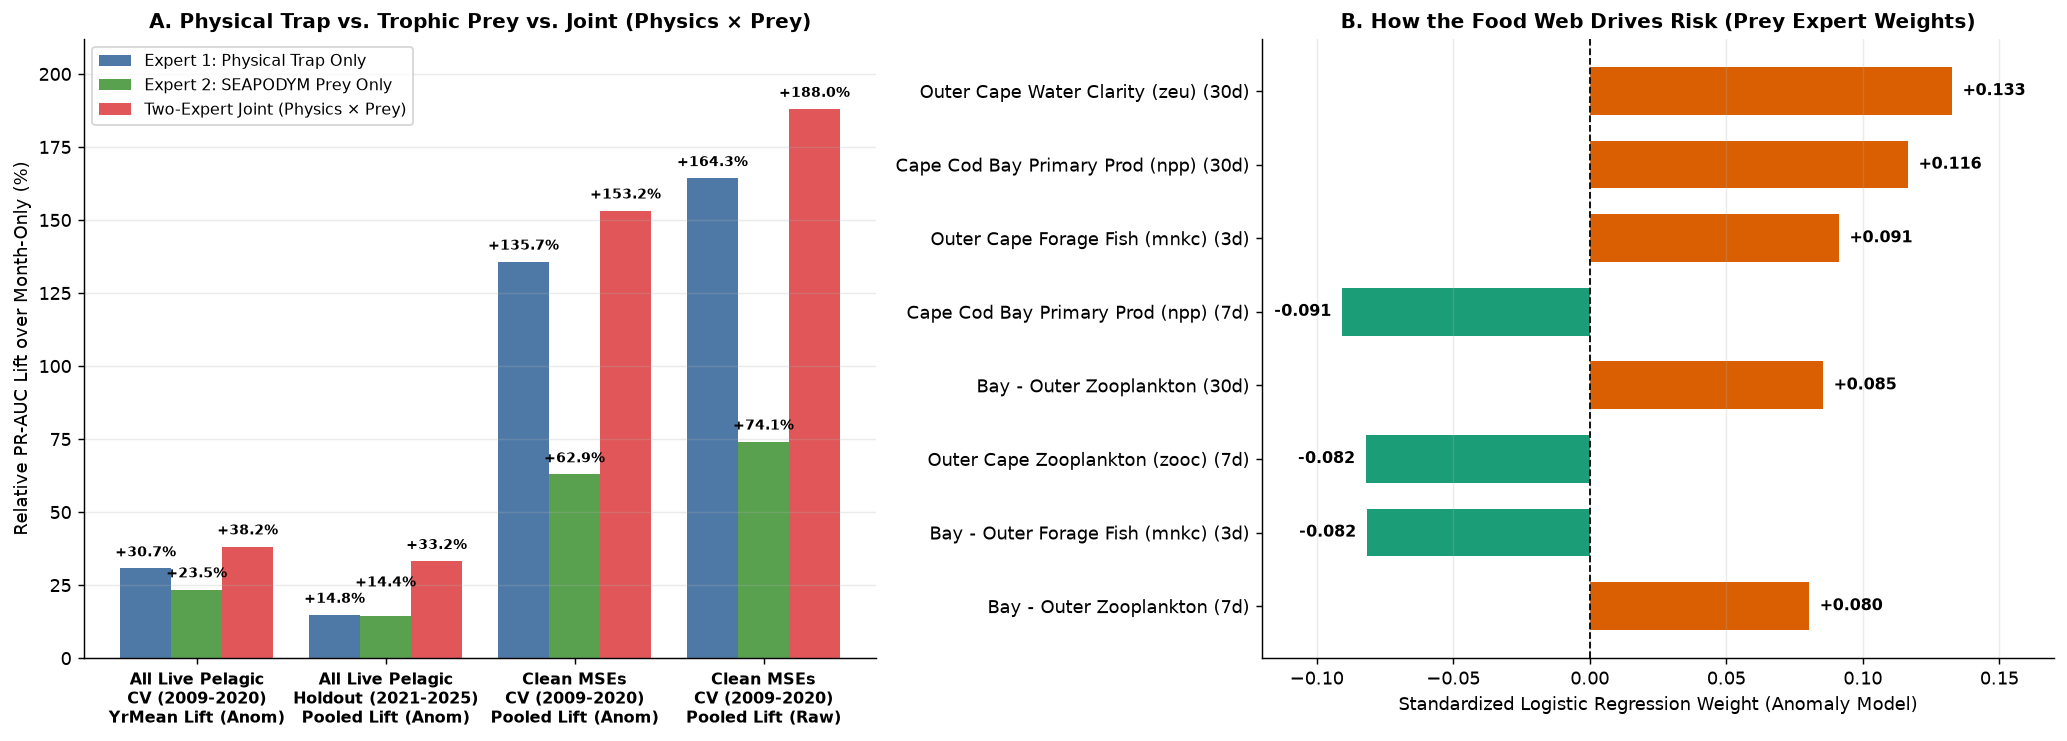

Saved figure: figures/04_trophic_prey_and_ensemble.png


In [4]:
# Visualize Figure 4: CV + Holdout Lift of Physics x Prey & Top Trophic Coefficients
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.8), dpi=130)

# Panel A: All-Events (y_live_odont_any) and MSE (y_live_odont_mse) Comparison across Expert 1, Expert 2, and Joint
labels = [
    "All Live Pelagic\n(CV 2009-2020\nYrMean Lift, Anom)",
    "All Live Pelagic\n(Holdout 2021-2025\nPooled Lift, Anom)",
    "Clean MSEs\n(CV 2009-2020\nYrMean Lift, Anom)",
    "Clean MSEs\n(Holdout 2021-2025\nPooled Lift, Raw)",
]

phys_vals = [
    cv_df[(cv_df.target=="y_live_odont_any") & (cv_df.model.str.startswith("1.")) & (cv_df.version=="anomaly")]["rel_lift_yrmean (%)"].iloc[0],
    ho_df[(ho_df.target=="y_live_odont_any") & (ho_df.model.str.startswith("1.")) & (ho_df.version=="anomaly")]["rel_lift_pooled (%)"].iloc[0],
    cv_df[(cv_df.target=="y_live_odont_mse") & (cv_df.model.str.startswith("1.")) & (cv_df.version=="anomaly")]["rel_lift_yrmean (%)"].iloc[0],
    ho_df[(ho_df.target=="y_live_odont_mse") & (ho_df.model.str.startswith("1.")) & (ho_df.version=="raw")]["rel_lift_pooled (%)"].iloc[0],
]
prey_vals = [
    cv_df[(cv_df.target=="y_live_odont_any") & (cv_df.model.str.startswith("2.")) & (cv_df.version=="anomaly")]["rel_lift_yrmean (%)"].iloc[0],
    ho_df[(ho_df.target=="y_live_odont_any") & (ho_df.model.str.startswith("2.")) & (ho_df.version=="anomaly")]["rel_lift_pooled (%)"].iloc[0],
    cv_df[(cv_df.target=="y_live_odont_mse") & (cv_df.model.str.startswith("2.")) & (cv_df.version=="anomaly")]["rel_lift_yrmean (%)"].iloc[0],
    ho_df[(ho_df.target=="y_live_odont_mse") & (ho_df.model.str.startswith("2.")) & (ho_df.version=="raw")]["rel_lift_pooled (%)"].iloc[0],
]
joint_vals = [
    cv_df[(cv_df.target=="y_live_odont_any") & (cv_df.model.str.startswith("3.")) & (cv_df.version=="anomaly")]["rel_lift_yrmean (%)"].iloc[0],
    ho_df[(ho_df.target=="y_live_odont_any") & (ho_df.model.str.startswith("3.")) & (ho_df.version=="anomaly")]["rel_lift_pooled (%)"].iloc[0],
    cv_df[(cv_df.target=="y_live_odont_mse") & (cv_df.model.str.startswith("3.")) & (cv_df.version=="anomaly")]["rel_lift_yrmean (%)"].iloc[0],
    ho_df[(ho_df.target=="y_live_odont_mse") & (ho_df.model.str.startswith("3.")) & (ho_df.version=="raw")]["rel_lift_pooled (%)"].iloc[0],
]

x = np.arange(len(labels))
w = 0.26
b1 = axes[0].bar(x - w, phys_vals, width=w, label="Expert 1: Physical Trap Only", color="#4e79a7")
b2 = axes[0].bar(x, prey_vals, width=w, label="Expert 2: SEAPODYM Prey Only", color="#59a14f")
b3 = axes[0].bar(x + w, joint_vals, width=w, label="Two-Expert Joint (Physics × Prey)", color="#e15759")

for bar in list(b1) + list(b2) + list(b3):
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 1.8, f"+{h:.1f}%", ha="center", va="bottom", fontsize=8.2, fontweight="bold")

axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, fontsize=8.8, fontweight="bold")
axes[0].set_ylabel("Relative PR-AUC Lift over Month-Only (%)", fontsize=10)
axes[0].set_ylim(0, 132)
axes[0].set_title("A. Physical Trap vs. Trophic Prey vs. Joint Model", fontsize=11, fontweight="bold")
axes[0].legend(loc="upper left", frameon=True, fontsize=9)
axes[0].grid(axis="y", alpha=0.25)
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)

# Panel B: Top Standardized Anomaly Coefficients in the Trophic/Prey Expert (y_live_odont_any)
s_any = top_prey_coefs["y_live_odont_any"].iloc[::-1]
clean_names = [
    k.replace("_anom", "")
     .replace("grad_bay_outer_zooc", "Bay - Outer Zooplankton")
     .replace("grad_bay_outer_mnkc_epi", "Bay - Outer Forage Fish (mnkc)")
     .replace("outer_mnkc_epi", "Outer Cape Forage Fish (mnkc)")
     .replace("outer_zooc", "Outer Cape Zooplankton (zooc)")
     .replace("bay_npp", "Cape Cod Bay Primary Prod (npp)")
     .replace("outer_zeu", "Outer Cape Water Clarity (zeu)")
     .replace("_mean_", " (") + ")"
    for k in s_any.index
]
bar_colors = ["#d95f02" if v > 0 else "#1b9e77" for v in s_any.values]
bars = axes[1].barh(clean_names, s_any.values, color=bar_colors, height=0.65)
axes[1].axvline(0, color="black", linewidth=1, linestyle="--")
for bar, v in zip(bars, s_any.values):
    offset = 0.004 if v >= 0 else -0.004
    ha = "left" if v >= 0 else "right"
    axes[1].text(v + offset, bar.get_y() + bar.get_height()/2, f"{v:+.3f}", va="center", ha=ha, fontsize=8.8, fontweight="bold")

axes[1].set_xlim(-0.12, 0.17)
axes[1].set_xlabel("Standardized Logistic Regression Weight (Anomaly Model)", fontsize=10)
axes[1].set_title("B. How the Food Web Drives Risk (Prey Expert Weights)", fontsize=11, fontweight="bold")
axes[1].grid(axis="x", alpha=0.25)
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)

plt.tight_layout()
fig.savefig(FIG_DIR / "04_trophic_prey_and_ensemble.png", bbox_inches="tight")
plt.show()
print("Saved figure: figures/04_trophic_prey_and_ensemble.png")